In [27]:
import pandas as pd
import matplotlib.pyplot as plt

In [28]:
sales=pd.read_csv('data/sales_clean.csv',parse_dates=['InvoiceDate'])  

In [29]:
is_product=sales['StockCode'].astype(str).str[0].str.isdigit()
products= sales[is_product]

In [30]:
product_revenue = products.groupby('StockCode').agg(Description=('Description', 'last'), Revenue=('Revenue', 'sum'))
product_revenue.sort_values('Revenue', ascending=False).head(10)

,Description,Revenue
StockCode,,
22423,REGENCY CAKESTAND 3 TIER,330590.32
85123A,CREAM HANGING HEART T-LIGHT HOLDER,261168.73
85099B,JUMBO BAG RED RETROSPOT,182680.98
47566,PARTY BUNTING,148318.28
84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49
22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29
79321,CHILLI LIGHTS,80540.88
22197,POPCORN HOLDER,79520.20
22386,JUMBO BAG PINK POLKADOT,76324.62


In [31]:
product_revenue['Revenue'].sum()


np.float64(19397038.95)

In [32]:
products['Revenue'].sum()

np.float64(19397038.950000003)

In [33]:
sales

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
1007905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
1007906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1007907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1007908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85


In [34]:
sales['Month']= sales['InvoiceDate'].dt.to_period('M')
sales.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,39.6,2009-12
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,59.5,2009-12
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom,30.6,2009-12
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom,45.0,2009-12


In [35]:
full_months=sales[sales['InvoiceDate']<'2011-12-01']
monthly_revenue = full_months.groupby("Month")['Revenue'].sum()

monthly_revenue.sort_values(ascending=False)

Month
2011-11    1503866.780
2010-11    1464293.142
2010-10    1161902.220
2011-10    1151263.730
2011-09    1056435.192
2010-09     921696.991
2010-03     830915.261
2009-12     822483.950
2010-12     821452.730
2011-05     769296.610
2011-06     760547.010
2010-06     749537.310
2011-08     746779.320
2011-07     718076.121
2011-03     716215.260
2010-08     695251.910
2010-04     678875.252
2010-05     657705.500
2010-01     651155.112
2010-07     648810.270
2011-01     612628.010
2010-02     551504.726
2011-04     536968.491
2011-02     522545.560
Freq: M, Name: Revenue, dtype: float64

In [36]:
sales['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

Text(0, 0.5, 'Revenue(£)')

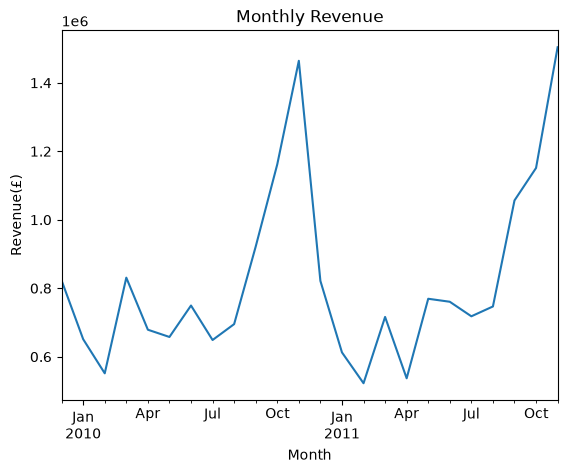

In [37]:

monthly_revenue.plot(kind='line')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue(£)')

In [38]:
in_season= products['InvoiceDate'].dt.month.isin([9,10,11])
in_season.value_counts()

InvoiceDate
False    642622
True     360590
Name: count, dtype: int64

In [39]:
season_revenue = products[in_season].groupby('StockCode')['Revenue'].sum()
season_revenue.head(10)

StockCode
10002     1762.88
10080       67.18
10120       47.04
10123C      48.94
10123G      84.22
10124A      13.44
10124G       5.88
10125      548.71
10133      288.34
10134       73.75
Name: Revenue, dtype: float64

In [40]:
product_revenue['SeasonShare']=(season_revenue/product_revenue['Revenue']*100).fillna(0)
product_revenue.head(10)

,Description,Revenue,SeasonShare
StockCode,,,
10002,INFLATABLE POLITICAL GLOBE,6942.26,25.393460
10002R,ROBOT PENCIL SHARPNER,20.57,0.000000
10080,GROOVY CACTUS INFLATABLE,129.29,51.960708
10109,BENDY COLOUR PENCILS,1.68,0.000000
10120,DOGGY RUBBER,142.74,32.955023
10123C,HEARTS WRAPPING TAPE,254.41,19.236665
10123G,ARMY CAMO WRAPPING TAPE,165.56,50.869775
10124A,SPOTS ON RED BOOKCOVER TAPE,24.36,55.172414
10124G,ARMY CAMO BOOKCOVER TAPE,14.28,41.176471


In [41]:
(product_revenue['Revenue']>=10000).sum()

np.int64(470)

In [42]:
main_products=product_revenue[product_revenue['Revenue']>=10000]
main_products.sort_values('SeasonShare',ascending=False).head(10)

,Description,Revenue,SeasonShare
StockCode,,,
22947,WOODEN ADVENT CALENDAR RED,12704.15,93.994718
22734,SET OF 6 RIBBONS VINTAGE CHRISTMAS,26763.75,92.560796
23356,LOVE HOT WATER BOTTLE,13334.32,91.538601
22812,PACK 3 BOXES CHRISTMAS PANETTONE,10734.43,91.129198
23581,JUMBO BAG PAISLEY PARK,11581.83,87.965891
22952,60 CAKE CASES VINTAGE CHRISTMAS,19240.05,87.406114
22580,ADVENT CALENDAR GINGHAM SACK,13141.08,87.357280
22866,HAND WARMER SCOTTY DOG DESIGN,28266.87,87.212663
22632,HAND WARMER RED RETROSPOT,20540.33,86.303920


In [43]:
products[products['StockCode']=='23581']['InvoiceDate'].min()

Timestamp('2011-10-25 10:31:00')

In [44]:
product_revenue['FirstSale']=products.groupby('StockCode')['InvoiceDate'].min()
main_products=product_revenue[(product_revenue['Revenue']>=10000) & (product_revenue['FirstSale']<'2011-01-01')]
main_products.sort_values('SeasonShare',ascending = False).head(10)

,Description,Revenue,SeasonShare,FirstSale
StockCode,,,,
22947,WOODEN ADVENT CALENDAR RED,12704.15,93.994718,2010-09-16 12:27:00
22734,SET OF 6 RIBBONS VINTAGE CHRISTMAS,26763.75,92.560796,2010-09-16 11:40:00
22812,PACK 3 BOXES CHRISTMAS PANETTONE,10734.43,91.129198,2010-09-15 13:36:00
22952,60 CAKE CASES VINTAGE CHRISTMAS,19240.05,87.406114,2010-09-17 15:04:00
22580,ADVENT CALENDAR GINGHAM SACK,13141.08,87.357280,2010-07-20 14:22:00
22866,HAND WARMER SCOTTY DOG DESIGN,28266.87,87.212663,2010-09-10 13:59:00
22632,HAND WARMER RED RETROSPOT,20540.33,86.303920,2010-09-20 15:33:00
22865,HAND WARMER OWL DESIGN,31416.04,85.335580,2010-09-10 13:59:00
22941,CHRISTMAS LIGHTS 10 REINDEER,21727.58,84.948485,2010-10-21 10:47:00


In [45]:
product_revenue.sort_values('Revenue',ascending=False).head(10)

,Description,Revenue,SeasonShare,FirstSale
StockCode,,,,
22423,REGENCY CAKESTAND 3 TIER,330590.32,34.290511,2010-03-15 13:55:00
85123A,CREAM HANGING HEART T-LIGHT HOLDER,261168.73,26.573070,2009-12-01 09:46:00
85099B,JUMBO BAG RED RETROSPOT,182680.98,35.144140,2009-12-01 10:06:00
47566,PARTY BUNTING,148318.28,17.187949,2009-12-01 13:07:00
84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,37.775220,2009-12-01 09:06:00
22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,72.175247,2009-12-01 10:06:00
79321,CHILLI LIGHTS,80540.88,43.959142,2009-12-01 14:56:00
22197,POPCORN HOLDER,79520.20,49.131994,2009-12-01 11:45:00
22386,JUMBO BAG PINK POLKADOT,76324.62,34.864019,2010-01-29 12:35:00


np.float64(-0.036510800786025116)

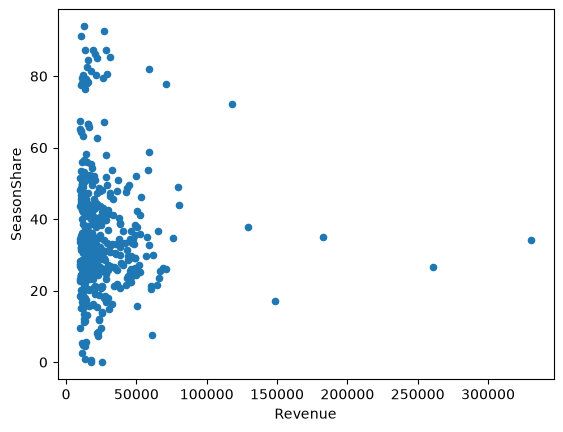

In [46]:
main_products.plot(kind='scatter',x='Revenue',y='SeasonShare')
main_products['Revenue'].corr(main_products['SeasonShare'])

In [47]:
customers = sales[sales['Customer ID'].notna()]
customers.shape

(779423, 10)

In [48]:
customer_summary= customers.groupby("Customer ID").agg(Revenue=('Revenue','sum'), Orders= ('Invoice','nunique'))
customer_summary.head()

,Revenue,Orders
Customer ID,,
12346.0,372.86,11
12347.0,4921.53,8
12348.0,2019.40,5
12349.0,4428.69,4
12350.0,334.40,1


In [49]:
len(customer_summary)
print(customer_summary.nlargest(10,'Revenue'))
customer_summary.nlargest(10, 'Orders')

               Revenue  Orders
Customer ID                   
18102.0      580987.04     145
14646.0      528602.52     151
14156.0      313437.62     156
14911.0      291420.81     398
17450.0      244784.25      51
13694.0      195640.69     143
17511.0      172132.87      60
16684.0      147142.77      55
12415.0      144458.37      28
15061.0      126389.02     127


,Revenue,Orders
Customer ID,,
14911.0,291420.81,398
12748.0,53539.64,336
17841.0,68545.25,211
15311.0,114966.42,208
13089.0,113416.91,203
14606.0,29951.37,192
14156.0,313437.62,156
17850.0,51208.87,155
14646.0,528602.52,151


In [50]:
top_value= customer_summary.nlargest(10,'Revenue')
top10_revenue=top_value['Revenue'].sum()
all_revenue = customer_summary['Revenue'].sum()
top10_revenue/all_revenue*100

np.float64(16.025288988945245)

In [69]:
sales_outside_UK= sales[sales['Country']!='United Kingdom']
total_revenue_outsideUK = sales_outside_UK.groupby("Country")['Revenue'].sum()
top10_revenue_outsideUK = total_revenue_outsideUK.nlargest(10)
top10_revenue_outsideUK


Country
EIRE           658767.310
Netherlands    554038.090
Germany        425019.711
France         350456.090
Australia      169283.460
Spain          108332.490
Switzerland    100685.590
Sweden          91869.820
Denmark         68580.690
Belgium         65387.820
Name: Revenue, dtype: float64

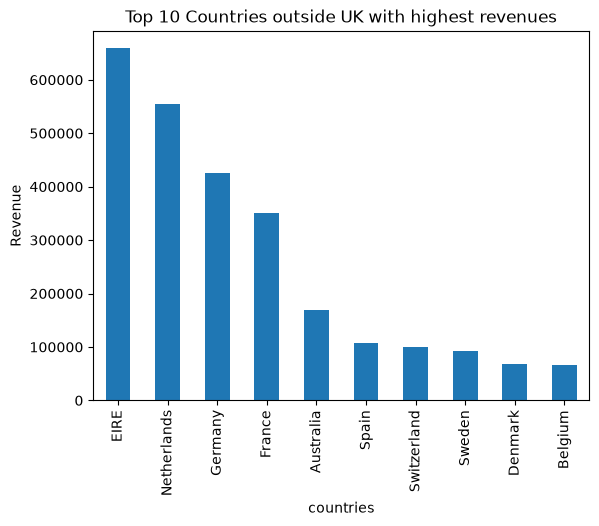

In [72]:
top10_revenue_outsideUK.plot(kind='bar',xlabel='countries',ylabel='Revenue',title='Top 10 Countries outside UK with highest revenues')
plt.show()

In [83]:
country_summary = sales_outside_UK.groupby('Country').agg(
    Revenue=('Revenue', 'sum'),
    Customers=('Customer ID', 'nunique')
)
country_summary.nlargest(10, 'Revenue')

,Revenue,Customers
Country,,
EIRE,658767.310,5
Netherlands,554038.090,22
Germany,425019.711,107
France,350456.090,95
Australia,169283.460,15
Spain,108332.490,41
Switzerland,100685.590,22
Sweden,91869.820,19
Denmark,68580.690,12
